# Heart Disease Prediction System


# Live Deployment Link

https://heartdiseasepredictiongi-gak7m7jmjh3higvhrgn5ob.streamlit.app/


# gitHub repo link

https://github.com/SamraAlam171/heart_disease_prediction.git

# Submitted by:
Samra Alam

SP24-BSE-137

B-section

# Task#2


# Table of Contents

- Step 1: Import Libraries
- Step 2: Load Heart Disease Dataset
- Step 3: Understand and Pre-process Heart Disease Data
  - Step 3.1: Understand the Dataset
  - Step 3.2: Handle Missing Values
  - Step 3.3: Prepare the Target Labels
- Step 4: Feature Extraction
  - Step 4.1: Select Exactly Four Input Attributes
  - Step 4.2: Define Input Vectors and Output Labels
- Step 5: Prepare the Input Features and Output Labels
  - Step 5.1: Understand the Dataset's Numeric Encodings
  - Step 5.2: Convert the Target into Binary Labels
  - Step 5.3: Verify the Final Feature Matrix
- Step 6: Execute the Training Phase
  - Step 6.1: Split Data into Training and Testing Sets
  - Step 6.2: Separate Training Inputs and Outputs
  - Step 6.3: Train the Support Vector Classifier
  - Step 6.4: Save the Trained Model
- Step 7: Execute the Testing Phase
  - Step 7.1: Separate Testing Inputs and Outputs
  - Step 7.2: Load the Saved Model
  - Step 7.3: Make Predictions on Testing Data
  - Step 7.4: Calculate the Accuracy Score
  - Step 7.5: Detailed Evaluation Metrics
    - Precision
    - Recall
    - F1-Score
    - Confusion Matrix
- Step 8: Execute the Application Phase
  - Step 8.1: Take Input from the User
  - Step 8.2: Create the Four-Feature Input Vector
  - Step 8.3: Validate and Prepare User Input
  - Step 8.4: Load the Saved Model
  - Step 8.5: Predict the Result
    - Step 8.5.1: Display the Prediction to the User
- Step 9: Execute the Feedback Phase
  - Step 9.1: Collect Feedback from Users and Domain Experts
  - Step 9.2: Identify Potential Improvements
  - Step 9.3: Improve and Re-evaluate the Model
- Step 10: Deploy the Model as a Public Web App
  - Step 10.1: Understand Model Deployment
  - Step 10.2: Create a GitHub Repository
  - Step 10.3: Create the Streamlit Web App
  - Step 10.4: Create requirements.txt
  - Step 10.5: Create a Streamlit Community Cloud Account
  - Step 10.6: Deploy the Application
  - Step 10.7: Troubleshoot Common Issues
  - Step 10.8: Share the Live Application Link


# Code — Heart Disease Prediction

# Step 1: Import Libraries

In [83]:

# Step 1: Import Libraries

import pandas as pd
import numpy as np
import pickle

# Data splitting
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Machine Learning model
from sklearn.svm import SVC

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Visualization
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


# Step 2: Load Heart Disease Dataset

In [111]:

# Step 2: Load Heart Disease Dataset

column_names = [
    "id", "age", "origin", "sex", "cp",
    "trestbps", "chol", "fbs", "restecg",
    "thalch", "exang", "oldpeak", "slope",
    "ca", "thal", "num"
]

heart_data = pd.read_csv(
    "heart_disease_uci.csv",
    na_values="?"
)

print("Dataset shape:", heart_data.shape)
print("Actual column names:")
print(heart_data.columns.tolist())

display(heart_data.head())


Dataset shape: (920, 16)
Actual column names:
['id', 'age', 'sex', 'dataset', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalch', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


# Step 3: Understand and Pre-process Heart Disease Data

# Step 3.1: Understand the Dataset

In [112]:
print(heart_data)

      id  age     sex        dataset               cp  trestbps   chol    fbs  \
0      1   63    Male      Cleveland   typical angina     145.0  233.0   True   
1      2   67    Male      Cleveland     asymptomatic     160.0  286.0  False   
2      3   67    Male      Cleveland     asymptomatic     120.0  229.0  False   
3      4   37    Male      Cleveland      non-anginal     130.0  250.0  False   
4      5   41  Female      Cleveland  atypical angina     130.0  204.0  False   
..   ...  ...     ...            ...              ...       ...    ...    ...   
915  916   54  Female  VA Long Beach     asymptomatic     127.0  333.0   True   
916  917   62    Male  VA Long Beach   typical angina       NaN  139.0  False   
917  918   55    Male  VA Long Beach     asymptomatic     122.0  223.0   True   
918  919   58    Male  VA Long Beach     asymptomatic       NaN  385.0   True   
919  920   62    Male  VA Long Beach  atypical angina     120.0  254.0  False   

              restecg  thal

In [113]:
heart_data.head(5)

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0


In [114]:

# Step 3.1: Understand the Dataset

print("Dataset Information:")
heart_data.info()

print("\nFirst Five Records:")
display(heart_data.head())

print("\nStatistical Summary:")
display(heart_data.describe())

print("\nMissing Values:")
print(heart_data.isnull().sum())


Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 920 entries, 0 to 919
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        920 non-null    int64  
 1   age       920 non-null    int64  
 2   sex       920 non-null    str    
 3   dataset   920 non-null    str    
 4   cp        920 non-null    str    
 5   trestbps  861 non-null    float64
 6   chol      890 non-null    float64
 7   fbs       830 non-null    object 
 8   restecg   918 non-null    str    
 9   thalch    865 non-null    float64
 10  exang     865 non-null    object 
 11  oldpeak   858 non-null    float64
 12  slope     611 non-null    str    
 13  ca        309 non-null    float64
 14  thal      434 non-null    str    
 15  num       920 non-null    int64  
dtypes: float64(5), int64(3), object(2), str(6)
memory usage: 115.1+ KB

First Five Records:


,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
0,1,63,Male,Cleveland,typical angina,145.0,233.0,True,lv hypertrophy,150.0,False,2.3,downsloping,0.0,fixed defect,0
1,2,67,Male,Cleveland,asymptomatic,160.0,286.0,False,lv hypertrophy,108.0,True,1.5,flat,3.0,normal,2
2,3,67,Male,Cleveland,asymptomatic,120.0,229.0,False,lv hypertrophy,129.0,True,2.6,flat,2.0,reversable defect,1
3,4,37,Male,Cleveland,non-anginal,130.0,250.0,False,normal,187.0,False,3.5,downsloping,0.0,normal,0
4,5,41,Female,Cleveland,atypical angina,130.0,204.0,False,lv hypertrophy,172.0,False,1.4,upsloping,0.0,normal,0



Statistical Summary:


,id,age,trestbps,chol,thalch,oldpeak,ca,num
count,920.000000,920.000000,861.000000,890.000000,865.000000,858.000000,309.000000,920.000000
mean,460.500000,53.510870,132.132404,199.130337,137.545665,0.878788,0.676375,0.995652
std,265.725422,9.424685,19.066070,110.780810,25.926276,1.091226,0.935653,1.142693
min,1.000000,28.000000,0.000000,0.000000,60.000000,-2.600000,0.000000,0.000000
25%,230.750000,47.000000,120.000000,175.000000,120.000000,0.000000,0.000000,0.000000
50%,460.500000,54.000000,130.000000,223.000000,140.000000,0.500000,0.000000,1.000000
75%,690.250000,60.000000,140.000000,268.000000,157.000000,1.500000,1.000000,2.000000
max,920.000000,77.000000,200.000000,603.000000,202.000000,6.200000,3.000000,4.000000



Missing Values:
id            0
age           0
sex           0
dataset       0
cp            0
trestbps     59
chol         30
fbs          90
restecg       2
thalch       55
exang        55
oldpeak      62
slope       309
ca          611
thal        486
num           0
dtype: int64


# Step 3.2: Handle Missing Values

In [115]:

# Step 3.2: Handle Missing Values

print("Missing values before cleaning:")
print(heart_data.isnull().sum().sum())

heart_data = heart_data.dropna().copy()

print("\nMissing values after cleaning:")
print(heart_data.isnull().sum().sum())

print("Cleaned dataset shape:", heart_data.shape)


Missing values before cleaning:
1759

Missing values after cleaning:
0
Cleaned dataset shape: (299, 16)


# Step 3.3: Prepare the Target Labels

In [116]:

# Step 3.3: Prepare the Target Labels

# Convert the original 'num' column into binary labels
heart_data["num"] = (heart_data["num"] > 0).astype(int)

print("Target distribution:")
print(heart_data["num"].value_counts())

print("\nTarget labels:")
print("0 = No heart disease recorded")
print("1 = Heart disease recorded")


Target distribution:
num
0    160
1    139
Name: count, dtype: int64

Target labels:
0 = No heart disease recorded
1 = Heart disease recorded


# Step 4: Feature Extraction

# Step 4.1: Select Exactly Four Input Attributes

In [117]:

# Rebuild the four-feature dataset

selected_features = ["age", "sex", "cp", "thalch"]

X = heart_data[selected_features].copy()
y = heart_data["num"].copy()

print("Input columns:", X.columns.tolist())
print("Data types:")
print(X.dtypes)

print("\nUnique sex values:", X["sex"].unique())
print("Unique chest pain values:", X["cp"].unique())


Input columns: ['age', 'sex', 'cp', 'thalch']
Data types:
age         int64
sex           str
cp            str
thalch    float64
dtype: object

Unique sex values: <StringArray>
['Male', 'Female']
Length: 2, dtype: str
Unique chest pain values: <StringArray>
['typical angina', 'asymptomatic', 'non-anginal', 'atypical angina']
Length: 4, dtype: str


# Step 4.2: Verify Input Vectors and Output Labels

In [118]:

# Step 4.2: Define Input Vectors and Output Labels

input_vectors = X
output_labels = y

display(input_vectors.head())

print("\nOutput labels:")
print(output_labels.head())


,age,sex,cp,thalch
0,63,Male,typical angina,150.0
1,67,Male,asymptomatic,108.0
2,67,Male,asymptomatic,129.0
3,37,Male,non-anginal,187.0
4,41,Female,atypical angina,172.0



Output labels:
0    0
1    1
2    1
3    0
4    0
Name: num, dtype: int64


# Define Input Vectors and Output Labels

In [119]:

# Step 4.2: Define Input Vectors and Output Labels

selected_features = ["age", "sex", "cp", "thalch"]

input_vectors = heart_data[selected_features].copy()
output_labels = heart_data["num"].copy()

print("Input Vectors:")
display(input_vectors.head())

print("\nOutput Labels:")
display(output_labels.head())

print("\nNumber of input attributes:", input_vectors.shape[1])


Input Vectors:


,age,sex,cp,thalch
0,63,Male,typical angina,150.0
1,67,Male,asymptomatic,108.0
2,67,Male,asymptomatic,129.0
3,37,Male,non-anginal,187.0
4,41,Female,atypical angina,172.0



Output Labels:


0    0
1    1
2    1
3    0
4    0
Name: num, dtype: int64


Number of input attributes: 4


# Step 5: Prepare the Input Features and Output Labels

# Step 5.1: Identify Categorical and Numerical Features

In [120]:

# Step 5.1: Identify Feature Types

print("Unique values in sex:")
print(input_vectors["sex"].unique())

print("\nUnique values in cp:")
print(input_vectors["cp"].unique())

print("\nMissing values in selected inputs:")
print(input_vectors.isnull().sum())


Unique values in sex:
<StringArray>
['Male', 'Female']
Length: 2, dtype: str

Unique values in cp:
<StringArray>
['typical angina', 'asymptomatic', 'non-anginal', 'atypical angina']
Length: 4, dtype: str

Missing values in selected inputs:
age       0
sex       0
cp        0
thalch    0
dtype: int64


# Step 5.2: Encode the Input Features

In [127]:

# Step 5.2: Prepare and Encode the Input Features

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

selected_features = ["age", "sex", "cp", "thalch"]

X = heart_data[selected_features].copy()
y = (heart_data["num"] > 0).astype(int)

numeric_features = ["age", "thalch"]
categorical_features = ["sex", "cp"]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_features)
    ]
)

print("Features prepared successfully!")
print("Input columns:", X.columns.tolist())
print("Number of input attributes:", X.shape[1])


Features prepared successfully!
Input columns: ['age', 'sex', 'cp', 'thalch']
Number of input attributes: 4


# Step 5.3: Verify the Final Feature Matrix

In [128]:

# Step 5.3: Verify the Final Feature Matrix

print("Input columns:", input_vectors.columns.tolist())
print("Number of input features:", input_vectors.shape[1])
print("Missing input values:", input_vectors.isnull().sum().sum())
print("Missing output values:", output_labels.isnull().sum())

print("\nTarget distribution:")
print(output_labels.value_counts().sort_index())


Input columns: ['age', 'sex', 'cp', 'thalch']
Number of input features: 4
Missing input values: 0
Missing output values: 0

Target distribution:
num
0    160
1    139
Name: count, dtype: int64


# Step 6: Execute the Training Phase

In [129]:
# Step 6.1: Split Data into Training and Testing Sets

In [130]:

# Step 6.1: Split Data into Training and Testing Sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=0,
    stratify=y
)

input_vector_train = X_train
output_label_train = y_train

input_vector_test = X_test
output_label_test = y_test

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (239, 4)
Testing data: (60, 4)


# Step 6.2: Separate Training Inputs and Outputs

In [131]:

# Step 6.2: Verify Training Inputs and Outputs

input_vector_train = input_train
output_label_train = output_train

print("Training input columns:")
print(input_vector_train.columns.tolist())

print("\nNumber of training features:", input_vector_train.shape[1])
print("Training labels:")
print(output_label_train.value_counts().sort_index())


Training input columns:
['age', 'sex', 'cp', 'thalch']

Number of training features: 4
Training labels:
num
0    128
1    111
Name: count, dtype: int64


# Step 6.3: Train the Support Vector Classifier

In [132]:

# Step 6.3: Train the Support Vector Classifier

svc_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", SVC(
        kernel="rbf",
        class_weight="balanced",
        random_state=0
    ))
])

svc_model.fit(input_vector_train, output_label_train)

print("Support Vector Classifier trained successfully!")
print("Original input attributes:", X_train.shape[1])


Support Vector Classifier trained successfully!
Original input attributes: 4


# Step 6.4: Save the Trained Model

In [133]:

# Step 6.4: Save the Trained Model

import pickle

with open("heart_disease_model.pkl", "wb") as file:
    pickle.dump(svc_model, file)

print("Saved: heart_disease_model.pkl")


Saved: heart_disease_model.pkl


In [134]:
# Step 7: Execute the Testing Phase

In [135]:

# Step 7.1: Prepare Testing Inputs and Outputs

input_vector_test = input_test
output_label_test = output_test

print("Testing input shape:", input_vector_test.shape)
print("Testing output shape:", output_label_test.shape)


Testing input shape: (60, 4)
Testing output shape: (60,)


# Step 7.2: Load the Saved Model

In [136]:

# Step 7.2: Load the Saved Model

with open("heart_disease_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

print("Saved model loaded successfully!")


Saved model loaded successfully!


# Step 7.3: Make Predictions on Testing Data

In [152]:

# Step 7.3: Make Predictions on Testing Data

predictions = loaded_model.predict(input_vector_test)

print("Actual labels:")
print(output_label_test.to_numpy())

print("\nPredicted labels:")
print(predictions)


Actual labels:
[1 1 1 1 1 1 1 1 1 1 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 1 0 0 1 0 0 0 1 1 0
 0 0 1 0 1 1 0 1 1 0 0 1 0 1 0 1 1 0 1 0 0 0 0]

Predicted labels:
[0 1 1 1 1 0 1 1 1 1 1 0 0 0 1 0 0 1 0 0 1 0 1 0 0 1 1 1 1 0 1 0 1 0 1 1 0
 0 1 0 0 0 1 0 1 1 0 0 1 0 1 0 1 1 1 1 0 0 0 0]


# Step 7.4: Calculate the Accuracy Score

In [138]:

# Step 7.4: Calculate the Accuracy Score

accuracy = accuracy_score(output_label_test, predictions)

print(f"Model Accuracy: {accuracy:.2%}")


Model Accuracy: 78.33%


# Step 7.5: Detailed Evaluation Metrics

Classification Report:
                 precision    recall  f1-score   support

     No Disease       0.83      0.75      0.79        32
Disease Present       0.74      0.82      0.78        28

       accuracy                           0.78        60
      macro avg       0.78      0.79      0.78        60
   weighted avg       0.79      0.78      0.78        60

Confusion Matrix:
[[24  8]
 [ 5 23]]


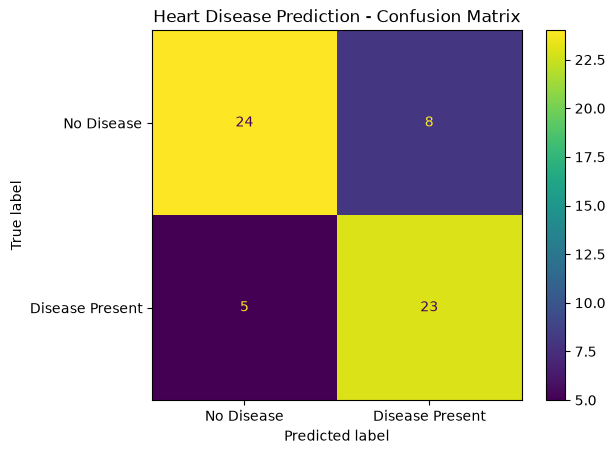

In [139]:

# Step 7.5: Detailed Evaluation Metrics

print("Classification Report:")
print(
    classification_report(
        output_label_test,
        predictions,
        target_names=["No Disease", "Disease Present"],
        zero_division=0
    )
)

cm = confusion_matrix(output_label_test, predictions)

print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Disease", "Disease Present"]
).plot()

plt.title("Heart Disease Prediction - Confusion Matrix")
plt.show()


# Next: Step 8 — Execute the Application Phase

# Step 8.1: Take Input from the User

In [153]:

# Step 8.1: Take Input from the User

age = float(input("Enter age in years: "))

print("\nSex options:", sorted(heart_data["sex"].dropna().unique()))
sex = input("Enter sex exactly as shown above: ").strip()

print("\nChest pain options:", sorted(heart_data["cp"].dropna().unique()))
cp = input("Enter chest pain type exactly as shown above: ").strip()

thalch = float(input("Enter maximum heart rate achieved: "))


Enter age in years:  22



Sex options: ['Female', 'Male']


Enter sex exactly as shown above:  Male



Chest pain options: ['asymptomatic', 'atypical angina', 'non-anginal', 'typical angina']


Enter chest pain type exactly as shown above:  asymptomatic
Enter maximum heart rate achieved:  155


# Step 8.2: Convert User Input into a Feature Vector

In [154]:

# Step 8.2: Convert User Input into Feature Vector

user_input = pd.DataFrame([{
    "age": age,
    "sex": sex,
    "cp": cp,
    "thalch": thalch
}])

print("User input:")
display(user_input)


User input:


,age,sex,cp,thalch
0,22.0,Male,asymptomatic,155.0


# Step 8.3: Encode the User Input

# Step 8.4: Load the Saved Model
# Step 8.5: Apply the Model and Display the Prediction

In [156]:

# Step 8.4: Load the Saved Model

with open("heart_disease_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

print("Model loaded successfully!")

# Step 8.5: Model Prediction

prediction = loaded_model.predict(user_input)[0]

print("Predicted class:", prediction)

if prediction == 0:
    print("The model predicts: No heart disease recorded.")
else:
    print("The model predicts: Heart disease recorded.")

print("\nEducational prediction only; not a medical diagnosis.")


Model loaded successfully!
Predicted class: 1
The model predicts: Heart disease recorded.

Educational prediction only; not a medical diagnosis.


# Step 9: Evaluate the model's accuracy

In [157]:

# Step 9: Evaluate Model Performance

from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(output_label_test, predictions)

print(f"Model Accuracy: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    output_label_test,
    predictions,
    target_names=["No Disease", "Disease Present"],
    zero_division=0
))


Model Accuracy: 78.33%

Classification Report:
                 precision    recall  f1-score   support

     No Disease       0.83      0.75      0.79        32
Disease Present       0.74      0.82      0.78        28

       accuracy                           0.78        60
      macro avg       0.78      0.79      0.78        60
   weighted avg       0.79      0.78      0.78        60

